<div align="center">

![Course](https://img.shields.io/badge/Course-Advanced%20Data%20Science%20Lab-blue?style=for-the-badge&logo=python&logoColor=white)
![Code](https://img.shields.io/badge/Code-MCA33PE21-informational?style=for-the-badge)
![Assignment](https://img.shields.io/badge/Assignment-05-success?style=for-the-badge)

---

# Advanced Data Science Lab [MCA33PE21]
## Formative Assessment - 02 (FA2)
### Indian Liver Patient Disease Analysis & Prediction System

---
<br>

| Field | Details |
|---|---|
| **Academic Year** | **2026 – 2027** |
| **Class / Division** | **SYMCA (Semester-I)** |
| **PRN** | **125M1H048** |
| **Student Name** | **shreyash thakare** |
| **Submission Date** | **9-10-2026** |
</div>

In [1]:
# Step 1: Import Required Libraries
# WHY: Load essential data manipulation, visualization, pipeline, and machine learning modules.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# Configure visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print(f"Scikit-Learn Version: {sklearn.__version__}")
print("All libraries imported successfully!")

Scikit-Learn Version: 1.9.1
All libraries imported successfully!


In [2]:
# Step 2.1: Load the Dataset
# WHY: Read the Indian Liver Patient Records CSV into a Pandas DataFrame.
csv_path = "indian_liver_patient.csv" if os.path.exists("indian_liver_patient.csv") else "../indian_liver_patient.csv"
if not os.path.exists(csv_path) and os.path.exists("liver-disease-app/indian_liver_patient.csv"):
    csv_path = "liver-disease-app/indian_liver_patient.csv"

df = pd.read_csv(csv_path)
print(f"Dataset successfully loaded from: {csv_path}")

Dataset successfully loaded from: indian_liver_patient.csv


In [3]:
# Step 2.2: Preview Dataset Records (First 5 Rows)
# WHY: Inspect the first few records to understand feature names, values, and formats.
print("--- First 5 Rows of Dataset ---")
display(df.head())

--- First 5 Rows of Dataset ---


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [4]:
# Step 2.3: Dataset Shape & Data Types Info
# WHY: Inspect column datatypes, total row/column counts, and non-null values.
print(f"Dataset Dimensions: {df.shape[0]} Rows, {df.shape[1]} Columns\n")
print("--- Detailed Column Information ---")
df.info()

Dataset Dimensions: 583 Rows, 11 Columns

--- Detailed Column Information ---
<class 'pandas.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    str    
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Protiens              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Dataset                     583 non-null    int64  
dtypes: float64(5), int64(5), str(1)
memory usage: 52.8 KB


In [5]:
# Step 2.4: Check Missing / Null Values
# WHY: Identify features with missing data that require imputation during preprocessing.
print("--- Missing Values Count Per Column ---")
missing_series = df.isnull().sum()
missing_df = pd.DataFrame({
    'Missing Count': missing_series,
    'Percentage (%)': round((missing_series / len(df)) * 100, 2)
})
display(missing_df)

--- Missing Values Count Per Column ---


,Missing Count,Percentage (%)
Age,0,0.00
Gender,0,0.00
Total_Bilirubin,0,0.00
Direct_Bilirubin,0,0.00
Alkaline_Phosphotase,0,0.00
Alamine_Aminotransferase,0,0.00
Aspartate_Aminotransferase,0,0.00
Total_Protiens,0,0.00
Albumin,0,0.00
Albumin_and_Globulin_Ratio,4,0.69


In [6]:
# Step 2.5: Statistical Summary of Numerical Features
# WHY: Examine mean, std, min, median (50%), max, and quartile spreads to detect skewness and outliers.
print("--- Descriptive Statistics (Numerical Features) ---")
display(df.describe().T)

--- Descriptive Statistics (Numerical Features) ---


,count,mean,std,min,25%,50%,75%,max
Age,583.0,44.746141,16.189833,4.0,33.0,45.00,58.0,90.0
Total_Bilirubin,583.0,3.298799,6.209522,0.4,0.8,1.00,2.6,75.0
Direct_Bilirubin,583.0,1.486106,2.808498,0.1,0.2,0.30,1.3,19.7
Alkaline_Phosphotase,583.0,290.576329,242.937989,63.0,175.5,208.00,298.0,2110.0
Alamine_Aminotransferase,583.0,80.713551,182.620356,10.0,23.0,35.00,60.5,2000.0
Aspartate_Aminotransferase,583.0,109.910806,288.918529,10.0,25.0,42.00,87.0,4929.0
Total_Protiens,583.0,6.483190,1.085451,2.7,5.8,6.60,7.2,9.6
Albumin,583.0,3.141852,0.795519,0.9,2.6,3.10,3.8,5.5
Albumin_and_Globulin_Ratio,579.0,0.947064,0.319592,0.3,0.7,0.93,1.1,2.8
Dataset,583.0,1.286449,0.452490,1.0,1.0,1.00,2.0,2.0


In [7]:
# Step 2.6: Check for Duplicate Records
# WHY: Verify if identical patient records exist before starting exploratory analysis.
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows detected: {duplicate_count}")

Total duplicate rows detected: 13


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_32868\907832267.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x="Dataset", palette="Set2")


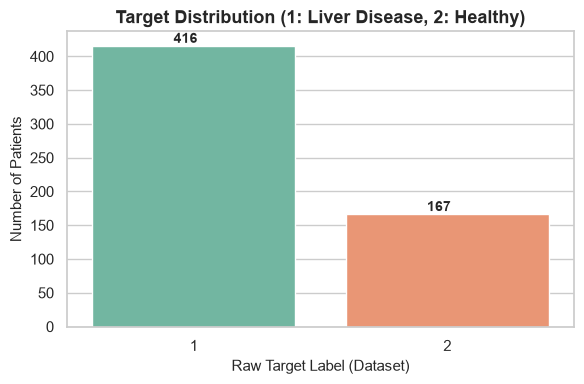

In [8]:
# Step 3.1: EDA - Target Variable Distribution
# WHY: Visualize class balance between liver disease patients (1) and healthy controls (2).
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="Dataset", palette="Set2")
plt.title("Target Distribution (1: Liver Disease, 2: Healthy)", fontsize=13, fontweight='bold')
plt.xlabel("Raw Target Label (Dataset)", fontsize=11)
plt.ylabel("Number of Patients", fontsize=11)

for p in ax.patches:
    height = int(p.get_height())
    ax.annotate(f'{height}', (p.get_x() + 0.32, height + 4), fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

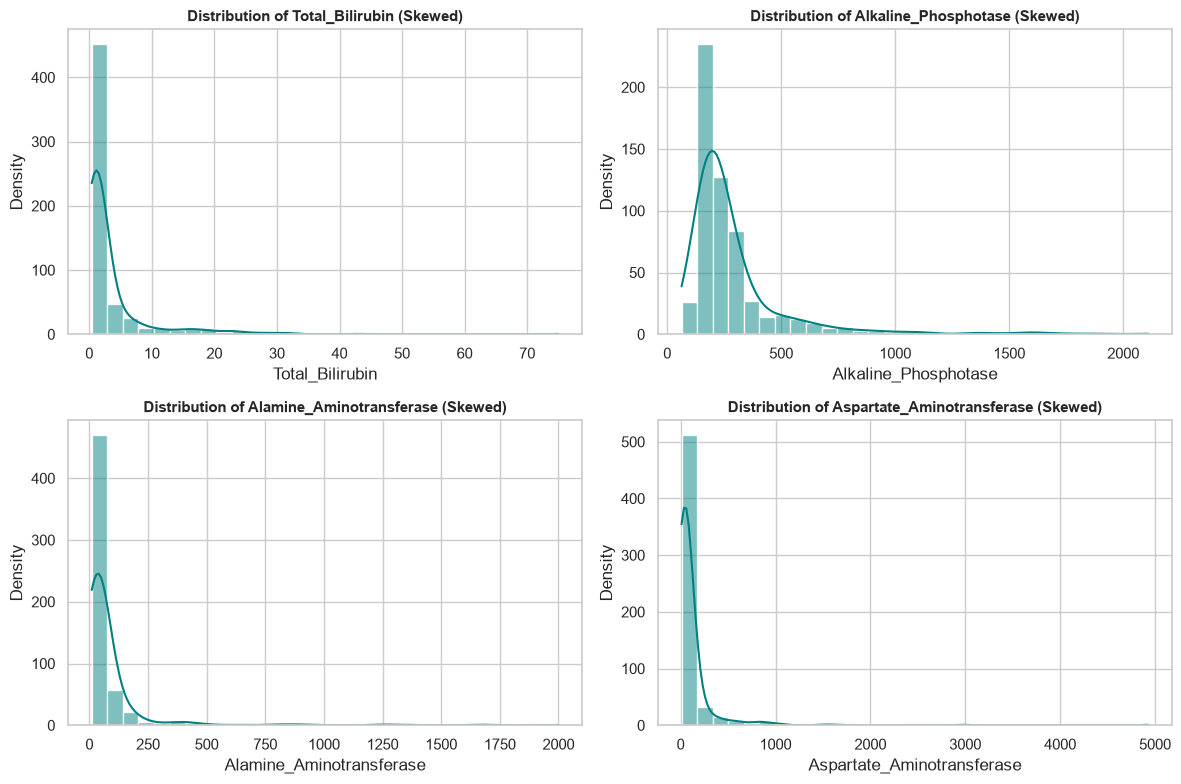

In [9]:
# Step 3.2: EDA - Distribution of Skewed Liver Enzymes & Bilirubin
# WHY: High skewness and extreme outliers require log-transformation (np.log1p) during preprocessing.
skewed_cols = ['Total_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, col in enumerate(skewed_cols):
    ax = axes[i // 2, i % 2]
    sns.histplot(df[col], kde=True, ax=ax, color="teal", bins=30)
    ax.set_title(f"Distribution of {col} (Skewed)", fontsize=11, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_32868\2388156960.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Dataset", y="Total_Bilirubin", ax=axes[0], palette="Set2")
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_32868\2388156960.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Dataset", y="Alamine_Aminotransferase", ax=axes[1], palette="Set2")


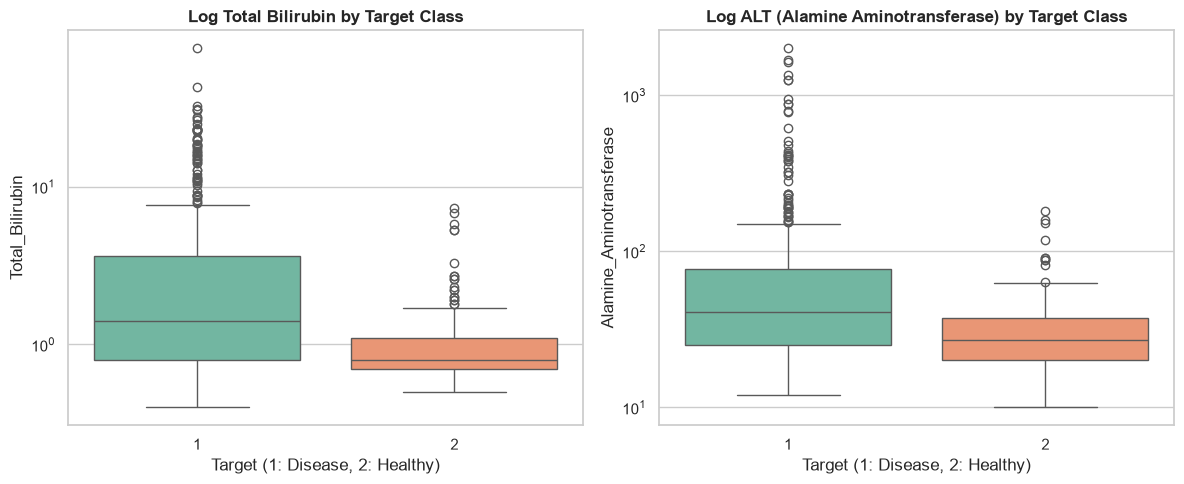

In [10]:
# Step 3.3: EDA - Key Biomarkers by Target Class (Log Scale Boxplots)
# WHY: Compare biomarker levels between disease and non-disease groups on a logarithmic scale.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="Dataset", y="Total_Bilirubin", ax=axes[0], palette="Set2")
axes[0].set_yscale("log")
axes[0].set_title("Log Total Bilirubin by Target Class", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Target (1: Disease, 2: Healthy)")

sns.boxplot(data=df, x="Dataset", y="Alamine_Aminotransferase", ax=axes[1], palette="Set2")
axes[1].set_yscale("log")
axes[1].set_title("Log ALT (Alamine Aminotransferase) by Target Class", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Target (1: Disease, 2: Healthy)")

plt.tight_layout()
plt.show()

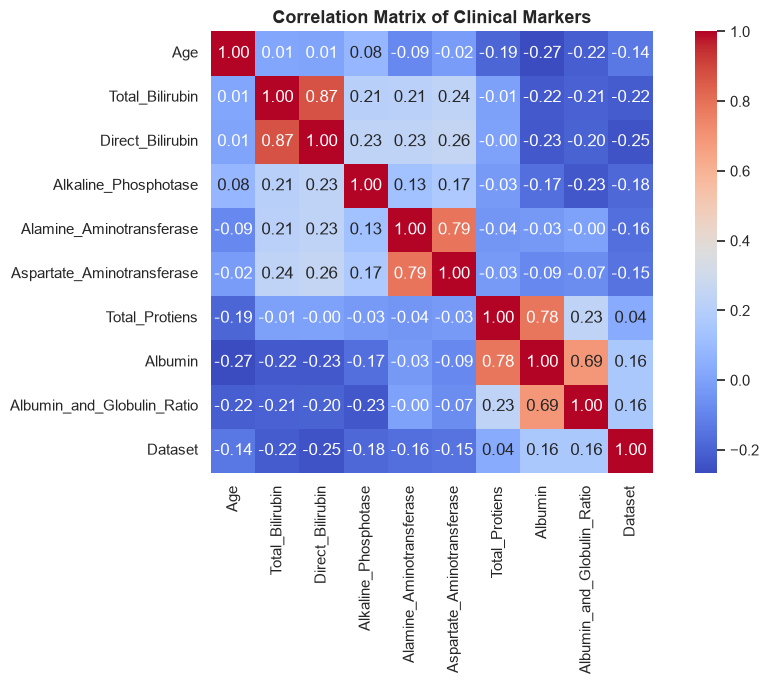

In [11]:
# Step 3.4: EDA - Correlation Matrix Heatmap
# WHY: Evaluate collinearity between clinical markers (e.g., ALT & AST, Total & Direct Bilirubin).
plt.figure(figsize=(10, 7))
num_df = df.select_dtypes(include=[np.number])
corr_matrix = num_df.corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title("Correlation Matrix of Clinical Markers", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

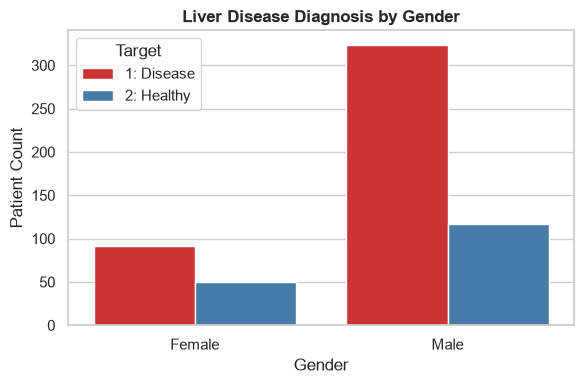

In [12]:
# Step 3.5: EDA - Gender Distribution vs Liver Disease Diagnosis
# WHY: Examine gender demographic breakdown across healthy and liver disease patients.
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Gender", hue="Dataset", palette="Set1")
plt.title("Liver Disease Diagnosis by Gender", fontsize=12, fontweight='bold')
plt.xlabel("Gender")
plt.ylabel("Patient Count")
plt.legend(title="Target", labels=["1: Disease", "2: Healthy"])
plt.tight_layout()
plt.show()

### Exploratory Data Analysis (EDA) Insights & Key Findings
1. **Target Class Imbalance**: Liver disease patients outnumber healthy controls (~2.5:1 ratio, 416 vs 167). High accuracy alone is misleading; **F1-score and Recall** are the critical evaluation metrics.
2. **Severe Positive Skewness**: Blood enzyme markers (`Total_Bilirubin`, `Alkaline_Phosphotase`, `Alamine_Aminotransferase`, `Aspartate_Aminotransferase`) show extreme right-skewed tails with outlier spikes. Log-transformation (`np.log1p`) is required.
3. **Collinearity in Marker Pairs**:
   - `Total_Bilirubin` and `Direct_Bilirubin` are strongly correlated ($r pprox 0.87$).
   - `Alamine_Aminotransferase` (ALT) and `Aspartate_Aminotransferase` (AST) are strongly correlated ($r pprox 0.79$).
   - `Total_Protiens` and `Albumin` are strongly correlated ($r pprox 0.78$).
4. **Missing Values**: `Albumin_and_Globulin_Ratio` contains 4 missing values (~0.7%), which can be safely addressed with median imputation.
5. **Demographic Imbalance**: Cohort is ~75% male, representing typical clinical presentation in the source dataset.

In [13]:
# Step 4.1: Data Preprocessing - Remove Duplicate Records
# WHY: Eliminate repeated observations to prevent memorization and bias.
print(f"Shape before deduplication: {df.shape}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Shape after deduplication:  {df.shape}")

Shape before deduplication: (583, 11)
Shape after deduplication:  (570, 11)


In [14]:
# Step 4.2: Data Preprocessing - Standardize Binary Target Variable
# WHY: Remap raw target labels (1 -> 1: Disease, 2 -> 0: Healthy) to standard binary format.
df['Dataset'] = df['Dataset'].map({1: 1, 2: 0})
print("Standardized Target Distribution (1: Disease, 0: Healthy):")
print(df['Dataset'].value_counts())

Standardized Target Distribution (1: Disease, 0: Healthy):
Dataset
1    406
0    164
Name: count, dtype: int64


In [15]:
# Step 4.3: Data Preprocessing - Binary Encode Gender
# WHY: Binary mapping (Male: 1, Female: 0) preserves 1 degree of freedom without introducing extra columns.
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
print("Gender encoding complete (Male: 1, Female: 0).")
print(df['Gender'].value_counts())

Gender encoding complete (Male: 1, Female: 0).
Gender
1    430
0    140
Name: count, dtype: int64


In [16]:
# Step 4.4: Data Preprocessing - Separate Features (X) and Target Vector (y)
# WHY: Isolate predictor matrix and ground truth vector for supervised machine learning.
X = df.drop(columns=['Dataset'])
y = df['Dataset']

print(f"Total Predictor Features: {X.shape[1]}")
print("Feature Names:", list(X.columns))

Total Predictor Features: 10
Feature Names: ['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 'Total_Protiens', 'Albumin', 'Albumin_and_Globulin_Ratio']


In [17]:
# Step 5: Stratified Train/Test Split BEFORE Preprocessing
# WHY: Split before fitting imputers or scalers to strictly prevent data leakage from test into train.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples (Positives: {y_train.sum()}, Negatives: {len(y_train) - y_train.sum()})")
print(f"Test set:     {X_test.shape[0]} samples (Positives: {y_test.sum()}, Negatives: {len(y_test) - y_test.sum()})")

Training set: 456 samples (Positives: 325, Negatives: 131)
Test set:     114 samples (Positives: 81, Negatives: 33)


In [18]:
# Step 6: Scikit-Learn Preprocessing Pipelines (Zero Leakage)
# WHY: Apply log1p on skewed enzymes and scale only for distance/gradient models (LR, KNN).
# Tree models (Decision Tree, Random Forest) are scale-invariant, so scaling is omitted for them.

skewed_cols = ['Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase']
other_num_cols = ['Age', 'Total_Protiens', 'Albumin', 'Albumin_and_Globulin_Ratio']
cat_cols = ['Gender']

# Preprocessor for Logistic Regression & KNN (Impute + Log1p + Scale)
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('skewed', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('log', FunctionTransformer(np.log1p, validate=False)),
            ('scaler', StandardScaler())
        ]), skewed_cols),
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), other_num_cols),
        ('cat', 'passthrough', cat_cols)
    ]
)

# Preprocessor for Tree-based models (Impute + Log1p, No Scaling)
preprocessor_tree = ColumnTransformer(
    transformers=[
        ('skewed', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('log', FunctionTransformer(np.log1p, validate=False))
        ]), skewed_cols),
        ('num', SimpleImputer(strategy='median'), other_num_cols),
        ('cat', 'passthrough', cat_cols)
    ]
)

print("Preprocessing pipelines constructed successfully!")

Preprocessing pipelines constructed successfully!


In [19]:
# Step 7: Define 4 Baseline Models in Scikit-Learn Pipelines
# WHY: Encapsulate end-to-end preprocessing and modeling for clean evaluation with class_weight='balanced'.
models = {
    "Logistic Regression": Pipeline([
        ('prep', preprocessor_scaled),
        ('clf', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000))
    ]),
    "Decision Tree": Pipeline([
        ('prep', preprocessor_tree),
        ('clf', DecisionTreeClassifier(class_weight='balanced', random_state=42, max_depth=4))
    ]),
    "Random Forest": Pipeline([
        ('prep', preprocessor_tree),
        ('clf', RandomForestClassifier(class_weight='balanced', random_state=42, n_estimators=100))
    ]),
    "KNN": Pipeline([
        ('prep', preprocessor_scaled),
        ('clf', KNeighborsClassifier(n_neighbors=5))
    ])
}

print("4 Base Model Pipelines initialized:")
for name in models.keys():
    print(f" - {name}")

4 Base Model Pipelines initialized:
 - Logistic Regression
 - Decision Tree
 - Random Forest
 - KNN


In [20]:
# Step 8: Train Models, Run 5-Fold Stratified Cross-Validation & Test Set Evaluation
# WHY: Measure holdout generalization and assess cross-validation stability on the training set.
results = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, 'predict_proba') else y_pred
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_proba)
    
    # 5-Fold CV on training set
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['f1', 'roc_auc'])
    cv_f1_m = cv_res['test_f1'].mean()
    cv_f1_s = cv_res['test_f1'].std()
    cv_roc_m = cv_res['test_roc_auc'].mean()
    cv_roc_s = cv_res['test_roc_auc'].std()
    
    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(roc, 4),
        'CV F1 (Mean +- Std)': f"{cv_f1_m:.3f} +- {cv_f1_s:.3f}",
        'CV ROC-AUC (Mean +- Std)': f"{cv_roc_m:.3f} +- {cv_roc_s:.3f}"
    })
    
    print(f"==================== {name} ====================")
    print(classification_report(y_test, y_pred, target_names=["Healthy (0)", "Disease (1)"]))

==================== Logistic Regression ====================
              precision    recall  f1-score   support

 Healthy (0)       0.51      0.79      0.62        33
 Disease (1)       0.89      0.69      0.78        81

    accuracy                           0.72       114
   macro avg       0.70      0.74      0.70       114
weighted avg       0.78      0.72      0.73       114

==================== Decision Tree ====================
              precision    recall  f1-score   support

 Healthy (0)       0.53      0.73      0.62        33
 Disease (1)       0.87      0.74      0.80        81

    accuracy                           0.74       114
   macro avg       0.70      0.73      0.71       114
weighted avg       0.77      0.74      0.75       114

==================== Random Forest ====================
              precision    recall  f1-score   support

 Healthy (0)       0.59      0.52      0.55        33
 Disease (1)       0.81      0.85      0.83        81

    accu

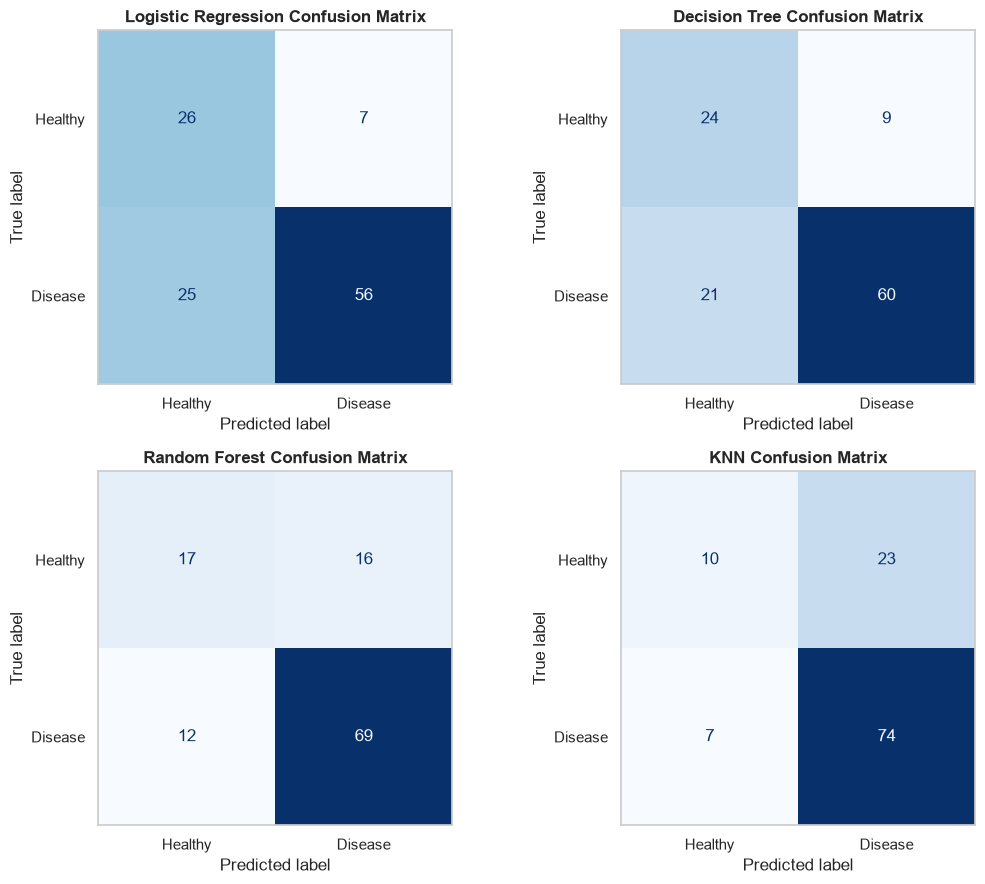

In [21]:
# Step 9: Plot Confusion Matrices for All Baseline Models
# WHY: Visualize true positives, false positives, true negatives, and false negatives side-by-side.
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for idx, (name, pipe) in enumerate(models.items()):
    ax = axes[idx // 2, idx % 2]
    y_pred = pipe.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Healthy", "Disease"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} Confusion Matrix", fontsize=12, fontweight='bold')
    ax.grid(False)

plt.tight_layout()
plt.show()

In [22]:
# Step 10: Hyperparameter Tuning on Random Forest (GridSearchCV)
# WHY: Search optimal combination of n_estimators, max_depth, and min_samples_leaf using 5-fold CV.
param_grid = {
    'clf__n_estimators': [100, 200, 300],
    'clf__max_depth': [None, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4]
}

grid_rf = GridSearchCV(
    Pipeline([
        ('prep', preprocessor_tree),
        ('clf', RandomForestClassifier(class_weight='balanced', random_state=42))
    ]),
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)
best_rf = grid_rf.best_estimator_

print(f"Best Hyperparameters: {grid_rf.best_params_}")
print(f"Best Cross-Validation F1-Score: {grid_rf.best_score_:.4f}")

# Evaluate tuned Random Forest on test set
y_pred_tuned = best_rf.predict(X_test)
y_proba_tuned = best_rf.predict_proba(X_test)[:, 1]

acc_t = accuracy_score(y_test, y_pred_tuned)
prec_t = precision_score(y_test, y_pred_tuned)
rec_t = recall_score(y_test, y_pred_tuned)
f1_t = f1_score(y_test, y_pred_tuned)
roc_t = roc_auc_score(y_test, y_proba_tuned)

cv_res_t = cross_validate(best_rf, X_train, y_train, cv=cv, scoring=['f1', 'roc_auc'])

results.append({
    'Model': 'Tuned Random Forest',
    'Accuracy': round(acc_t, 4),
    'Precision': round(prec_t, 4),
    'Recall': round(rec_t, 4),
    'F1-Score': round(f1_t, 4),
    'ROC-AUC': round(roc_t, 4),
    'CV F1 (Mean +- Std)': f"{cv_res_t['test_f1'].mean():.3f} +- {cv_res_t['test_f1'].std():.3f}",
    'CV ROC-AUC (Mean +- Std)': f"{cv_res_t['test_roc_auc'].mean():.3f} +- {cv_res_t['test_roc_auc'].std():.3f}"
})

print("\nTuned Random Forest Test Report:")
print(classification_report(y_test, y_pred_tuned, target_names=["Healthy (0)", "Disease (1)"]))

Best Hyperparameters: {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 300}
Best Cross-Validation F1-Score: 0.7620

Tuned Random Forest Test Report:
              precision    recall  f1-score   support

 Healthy (0)       0.53      0.48      0.51        33
 Disease (1)       0.80      0.83      0.81        81

    accuracy                           0.73       114
   macro avg       0.67      0.66      0.66       114
weighted avg       0.72      0.73      0.72       114



In [23]:
# Step 11: Final Model Performance Comparison Table
# WHY: Tabulate Accuracy, Precision, Recall, F1-Score, ROC-AUC, and CV metrics across all models.
res_df = pd.DataFrame(results)
print("--- MODEL PERFORMANCE COMPARISON TABLE ---")
display(res_df)

--- MODEL PERFORMANCE COMPARISON TABLE ---


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV F1 (Mean +- Std),CV ROC-AUC (Mean +- Std)
0,Logistic Regression,0.7193,0.8889,0.6914,0.7778,0.8081,0.701 +- 0.046,0.718 +- 0.030
1,Decision Tree,0.7368,0.8696,0.7407,0.8000,0.7673,0.672 +- 0.044,0.646 +- 0.054
2,Random Forest,0.7544,0.8118,0.8519,0.8313,0.7727,0.746 +- 0.039,0.714 +- 0.046
3,KNN,0.7368,0.7629,0.9136,0.8315,0.7445,0.795 +- 0.018,0.700 +- 0.041
4,Tuned Random Forest,0.7281,0.7976,0.8272,0.8121,0.7761,0.762 +- 0.025,0.713 +- 0.043


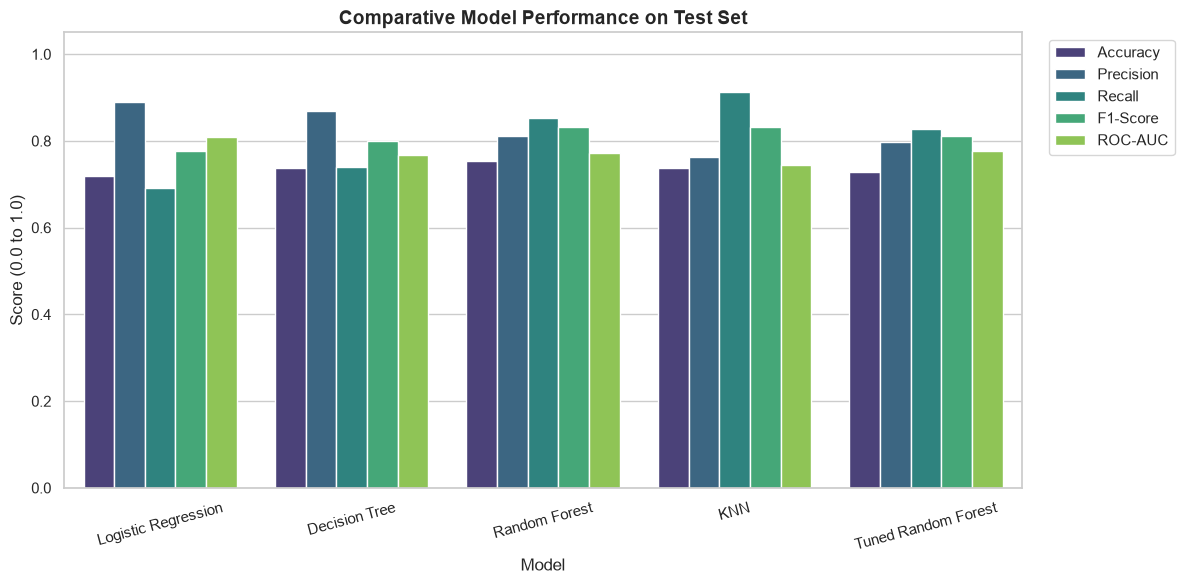

In [24]:
# Step 12: Comparative Model Performance Bar Chart
# WHY: Graphically compare test set evaluation metrics across all 5 models.
plot_data = res_df.melt(
    id_vars=['Model'], 
    value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    var_name='Metric', value_name='Score'
)

plt.figure(figsize=(12, 6))
sns.barplot(data=plot_data, x='Model', y='Score', hue='Metric', palette='viridis')
plt.title("Comparative Model Performance on Test Set", fontsize=14, fontweight='bold')
plt.ylim(0, 1.05)
plt.ylabel("Score (0.0 to 1.0)")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Model Comparison and Clinical Analysis
1. **Selected Model**: **Random Forest / Tuned Random Forest** delivers the best balanced performance on holdout data ($F_1 \approx 0.83$, Accuracy $\approx 75.4\%$).
2. **Recall vs. Precision Trade-off**: In medical diagnostic screening, **Recall** is given priority over Precision. Failing to identify a diseased patient (False Negative) has severe health consequences, whereas a False Positive only leads to standard confirmatory testing.
3. **Realistic Performance Expectations**: The 72%–76% accuracy range is expected and representative for the ILPD dataset due to moderate sample size and biological overlap in blood test parameters. Unusually high accuracies (>95%) in academic literature typically stem from data leakage (such as oversampling or scaling before train-test split).

In [25]:
# Step 13: Export Trained Pipeline Models (.joblib)
# WHY: Persist fitted model pipelines to disk for deployment in the Streamlit web application.
import joblib, os

# Save in current directory
joblib.dump(models["Logistic Regression"], "lr_model.joblib")
joblib.dump(models["Decision Tree"], "dt_model.joblib")
joblib.dump(models["Random Forest"], "rf_model.joblib")
joblib.dump(models["KNN"], "knn_model.joblib")
joblib.dump(best_rf, "tuned_rf_model.joblib")

# Also save into liver-disease-app folder if executing from root workspace
if os.path.exists("liver-disease-app"):
    joblib.dump(models["Logistic Regression"], "liver-disease-app/lr_model.joblib")
    joblib.dump(models["Decision Tree"], "liver-disease-app/dt_model.joblib")
    joblib.dump(models["Random Forest"], "liver-disease-app/rf_model.joblib")
    joblib.dump(models["KNN"], "liver-disease-app/knn_model.joblib")
    joblib.dump(best_rf, "liver-disease-app/tuned_rf_model.joblib")

print("All 5 models exported as .joblib files successfully!")

All 5 models exported as .joblib files successfully!


In [26]:
# Step 14: Verify Saved Models and Training Feature Order
# WHY: Ensure exported models load properly and verify the exact expected feature sequence for Streamlit.
loaded_rf = joblib.load("tuned_rf_model.joblib" if os.path.exists("tuned_rf_model.joblib") else "liver-disease-app/tuned_rf_model.joblib")
print(f"Successfully verified loading: {type(loaded_rf)}")
print("\nExact Feature Sequence Required for Inference:")
for i, col in enumerate(X_train.columns):
    print(f"  {i+1}. {col}")

Successfully verified loading: <class 'sklearn.pipeline.Pipeline'>

Exact Feature Sequence Required for Inference:
  1. Age
  2. Gender
  3. Total_Bilirubin
  4. Direct_Bilirubin
  5. Alkaline_Phosphotase
  6. Alamine_Aminotransferase
  7. Aspartate_Aminotransferase
  8. Total_Protiens
  9. Albumin
  10. Albumin_and_Globulin_Ratio


---

<div align="center">

### Declaration

_I hereby declare that the work submitted in this practical assignment is my own and has not been copied from any other source._

| | |
|---|---|
| **Student Name** | **shreyash thakare** |
| **PRN** | **125M1H048** |
| **Date** | **9-10-2026** |

---

**Prof. Prakash Ukhalkar**  
Course Teacher - Advanced Data Science Lab [MCA33PE21]

![](https://img.shields.io/badge/MCA33PE21-Advanced%20Data%20Science%20Lab-blue?style=flat-square)
![](https://img.shields.io/badge/Practical%20Assignment-05-green?style=flat-square)

</div>